In [34]:
import kagglehub

dataset_path = kagglehub.dataset_download(
    "paultimothymooney/chest-xray-pneumonia"
)

print("Dataset location:", dataset_path)

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Dataset location: /kaggle/input/chest-xray-pneumonia


In [35]:
import os

dataset_path = "/kaggle/input/chest-xray-pneumonia"

for root, dirs, files in os.walk(dataset_path):
    print(root, ":", len(files), "files")

/kaggle/input/chest-xray-pneumonia : 0 files
/kaggle/input/chest-xray-pneumonia/chest_xray : 0 files
/kaggle/input/chest-xray-pneumonia/chest_xray/chest_xray : 1 files
/kaggle/input/chest-xray-pneumonia/chest_xray/chest_xray/val : 1 files
/kaggle/input/chest-xray-pneumonia/chest_xray/chest_xray/val/PNEUMONIA : 9 files
/kaggle/input/chest-xray-pneumonia/chest_xray/chest_xray/val/NORMAL : 9 files
/kaggle/input/chest-xray-pneumonia/chest_xray/chest_xray/test : 1 files
/kaggle/input/chest-xray-pneumonia/chest_xray/chest_xray/test/PNEUMONIA : 390 files
/kaggle/input/chest-xray-pneumonia/chest_xray/chest_xray/test/NORMAL : 234 files
/kaggle/input/chest-xray-pneumonia/chest_xray/chest_xray/train : 1 files
/kaggle/input/chest-xray-pneumonia/chest_xray/chest_xray/train/PNEUMONIA : 3876 files
/kaggle/input/chest-xray-pneumonia/chest_xray/chest_xray/train/NORMAL : 1342 files
/kaggle/input/chest-xray-pneumonia/chest_xray/__MACOSX : 1 files
/kaggle/input/chest-xray-pneumonia/chest_xray/__MACOSX/che

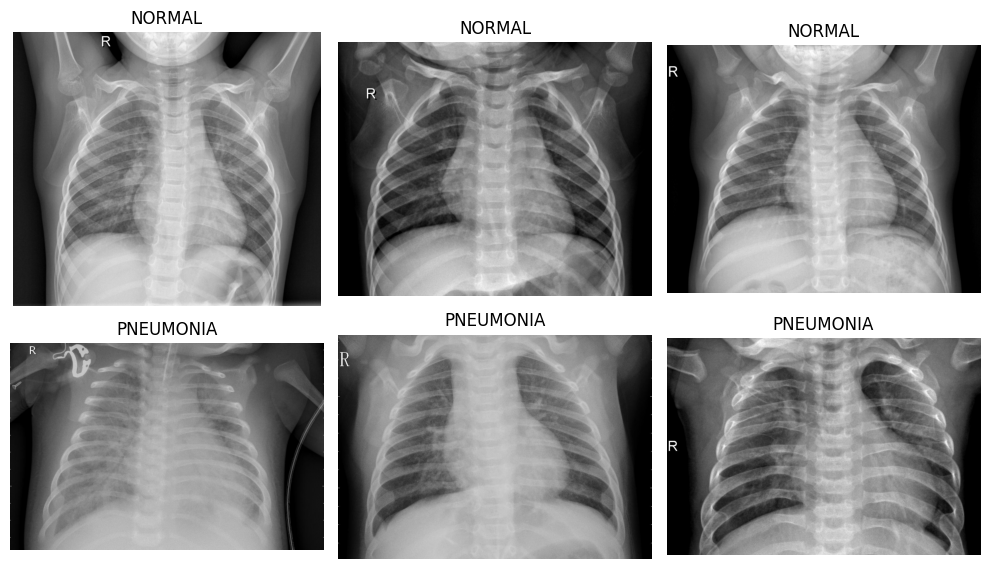

In [36]:

import os
import matplotlib.pyplot as plt
from PIL import Image

# Path to the training images
train_path = os.path.join(
    dataset_path, "chest_xray", "chest_xray", "train"
)

# Select the two categories
categories = ["NORMAL", "PNEUMONIA"]

plt.figure(figsize=(10, 6))

for i, category in enumerate(categories):

    folder = os.path.join(train_path, category)

    images = sorted([
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpeg", ".jpg", ".png"))
    ])

    for j in range(3):

        image_path = os.path.join(folder, images[j])

        image = Image.open(image_path).convert("L")

        plt.subplot(2, 3, i * 3 + j + 1)
        plt.imshow(image, cmap="gray")
        plt.title(category)
        plt.axis("off")

plt.tight_layout()
plt.show()


La pneumonie est une infection respiratoire qui provoque une inflammation des poumons et un remplissage des alvéoles par du liquide ou du pus.

In [37]:

from PIL import Image
import os
import numpy as np

# Select one image from the NORMAL category
normal_folder = os.path.join(train_path, "NORMAL")

image_name = sorted([
    f for f in os.listdir(normal_folder)
    if f.lower().endswith((".jpeg", ".jpg", ".png"))
])[0]

image_path = os.path.join(normal_folder, image_name)

# Open the image in grayscale
image = Image.open(image_path).convert("L")

# Convert the image to a NumPy array
image_array = np.array(image)

print("Image dimensions:", image.size)
print("Array shape:", image_array.shape)
print("Minimum pixel value:", image_array.min())
print("Maximum pixel value:", image_array.max())


Image dimensions: (2090, 1858)
Array shape: (1858, 2090)
Minimum pixel value: 0
Maximum pixel value: 255


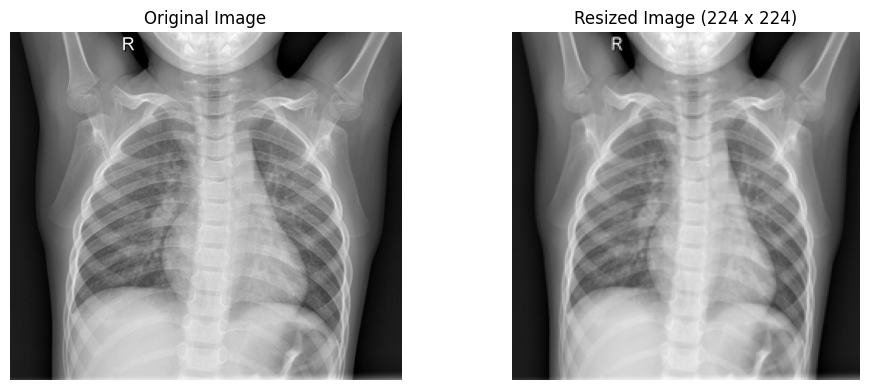

In [38]:
# Resize the image
resized_image = image.resize((224, 224))

# Display original and resized images
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(resized_image, cmap="gray")
plt.title("Resized Image (224 x 224)")
plt.axis("off")

plt.tight_layout()
plt.show()


In [39]:

import numpy as np

# Convert resized image into numerical values
image_array = np.array(resized_image)

# Normalize the pixels
normalized_image = image_array / 255.0

# Check the results
print("Image shape:", normalized_image.shape)
print("Minimum value:", normalized_image.min())
print("Maximum value:", normalized_image.max())

Image shape: (224, 224)
Minimum value: 0.0
Maximum value: 0.9764705882352941


In [40]:

import tensorflow as tf
import os

# Path to our training dataset
train_path = os.path.join(
    dataset_path,
    "chest_xray",
    "chest_xray",
    "train"
)

# Load the training images
train_dataset = tf.keras.utils.image_dataset_from_directory(
    train_path,
    labels="inferred",
    label_mode="binary",
    color_mode="grayscale",
    image_size=(224, 224),
    batch_size=32,
    shuffle=True,
    seed=42
)

print("Classes:", train_dataset.class_names)

Found 5216 files belonging to 2 classes.
Classes: ['NORMAL', 'PNEUMONIA']


In [41]:

from sklearn.model_selection import train_test_split
from pathlib import Path

# Collect the image paths and labels
image_paths = []
labels = []

for label, category in enumerate(["NORMAL", "PNEUMONIA"]):
    folder = Path(train_path) / category

    for path in sorted(folder.iterdir()):
        if path.suffix.lower() in [".jpeg", ".jpg", ".png"]:
            image_paths.append(str(path))
            labels.append(label)

# Split: 80% training, 20% validation
train_files, val_files, train_labels, val_labels = train_test_split(
    image_paths,
    labels,
    test_size=0.20,
    random_state=42,
    stratify=labels
)

print("Training images:", len(train_files))
print("Validation images:", len(val_files))

Training images: 4172
Validation images: 1044


In [42]:

import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

def load_image(path, label):

    # Read the image file
    image = tf.io.read_file(path)

    # Decode the image into pixels
    image = tf.io.decode_image(
        image,
        channels=1,
        expand_animations=False
    )

    # Resize to 224 x 224
    image = tf.image.resize(image, IMG_SIZE)

    # Normalize pixels between 0 and 1
    image = tf.cast(image, tf.float32) / 255.0

    return image, label

In [43]:

# Create training dataset
train_ds = tf.data.Dataset.from_tensor_slices(
    (train_files, train_labels)
)

# Create validation dataset
val_ds = tf.data.Dataset.from_tensor_slices(
    (val_files, val_labels)
)

# Prepare training images
train_ds = (
    train_ds
    .shuffle(len(train_files), seed=42)
    .map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

# Prepare validation images
val_ds = (
    val_ds
    .map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

print("Datasets are ready!")

Datasets are ready!


In [44]:

for images, labels in train_ds.take(1):

    print("Images shape:", images.shape)
    print("Labels shape:", labels.shape)

    print("Minimum pixel:", tf.reduce_min(images).numpy())
    print("Maximum pixel:", tf.reduce_max(images).numpy())

Images shape: (32, 224, 224, 1)
Labels shape: (32,)
Minimum pixel: 0.0
Maximum pixel: 1.0


3. Difference between NumPy, TensorFlow and Keras
Tool	Main purpose


**NumPy**	Work with numerical arrays and mathematical calculations.


**TensorFlow**	Perform numerical computations and train Machine Learning
models.

**Keras**	A high-level API that makes building neural networks easier.


CNN stands for Convolutional Neural Network.
It's a type of Deep Learning model especially useful for analyzing images.
Instead of manually telling the computer which visual patterns to look for, we train the CNN to learn useful patterns from labeled examples.

In [45]:

from tensorflow.keras import layers, models

model = models.Sequential([

    # First convolution layer
    layers.Input(shape=(224, 224, 1)),
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Second convolution layer
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Third convolution layer
    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Convert feature maps to a vector
    layers.Flatten(),

    # Classification layers
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),

    # Output layer
    layers.Dense(1, activation="sigmoid")
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 222, 222, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,168,513 (42.60 MB)

 Trainable params: 11,168,513 (42.60 MB)

 Non-trainable params: 0 (0.00 B)

Optimizer: how to update its parameters.



Loss function: how to measure prediction errors.



Metrics: how to measure performance.

In [46]:

from tensorflow.keras.optimizers import Adam
from tensorflow.keras.metrics import (
    BinaryAccuracy,
    Precision,
    Recall,
    AUC
)

model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss="binary_crossentropy",
    metrics=[
        BinaryAccuracy(name="accuracy"),
        Precision(name="precision"),
        Recall(name="recall"),
        AUC(name="auc")
    ]
)

print("Model compiled successfully!")


Model compiled successfully!


**Adam(learning_rate=0.0001)**
Adam is an optimization algorithm. It adjusts the model's parameters to reduce errors during training.
The learning rate controls the size of those adjustments.

we modified the gpu from processeur to gpu T4

In [47]:

from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[early_stopping]
)

Epoch 1/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 40s 239ms/step - accuracy: 0.8229 - auc: 0.8619 - loss: 0.3938 - precision: 0.8215 - recall: 0.9729 - val_accuracy: 0.9330 - val_auc: 0.9800 - val_loss: 0.1867 - val_precision: 0.9822 - val_recall: 0.9265
Epoch 2/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 27s 173ms/step - accuracy: 0.9382 - auc: 0.9792 - loss: 0.1643 - precision: 0.9537 - recall: 0.9635 - val_accuracy: 0.9655 - val_auc: 0.9916 - val_loss: 0.1041 - val_precision: 0.9793 - val_recall: 0.9742
Epoch 3/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 23s 173ms/step - accuracy: 0.9511 - auc: 0.9861 - loss: 0.1329 - precision: 0.9632 - recall: 0.9713 - val_accuracy: 0.9646 - val_auc: 0.9918 - val_loss: 0.0969 - val_precision: 0.9743 - val_recall: 0.9781
Epoch 4/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 23s 177ms/step - accuracy: 0.9581 - auc: 0.9903 - loss: 0.1110 - precision: 0.9710 - recall: 0.9726 - val_accuracy: 0.9550 - val_auc: 0.9926 - val_loss: 0.1141 - val_precision: 0.9932 - val_recall: 0.9459
Epoch 5/10
131/131 ━

In [48]:
!pip install -q plotly

In [49]:

import plotly.graph_objects as go
import numpy as np

# Get real metrics from our trained CNN
epochs = np.arange(
    1, len(history.history["accuracy"]) + 1
)

train_acc = np.array(history.history["accuracy"])
val_acc = np.array(history.history["val_accuracy"])

train_loss = np.array(history.history["loss"])
val_loss = np.array(history.history["val_loss"])

fig = go.Figure()

# Training journey
fig.add_trace(go.Scatter3d(
    x=epochs,
    y=train_acc * 100,
    z=train_loss,
    mode="lines+markers",
    name="Training",
    line=dict(color="#00E5FF", width=8),
    marker=dict(size=6, color="#00E5FF"),
    hovertemplate=(
        "Epoch: %{x}<br>"
        "Accuracy: %{y:.2f}%<br>"
        "Loss: %{z:.4f}<extra></extra>"
    )
))

# Validation journey
fig.add_trace(go.Scatter3d(
    x=epochs,
    y=val_acc * 100,
    z=val_loss,
    mode="lines+markers",
    name="Validation",
    line=dict(color="#FF4FD8", width=8),
    marker=dict(size=6, color="#FF4FD8"),
    hovertemplate=(
        "Epoch: %{x}<br>"
        "Accuracy: %{y:.2f}%<br>"
        "Loss: %{z:.4f}<extra></extra>"
    )
))

# Futuristic dashboard styling
fig.update_layout(
    title=dict(
        text="NEUROVISION | CNN Learning Journey",
        x=0.5,
        font=dict(size=23, color="white")
    ),
    paper_bgcolor="#080D1B",
    font=dict(color="white"),
    scene=dict(
        xaxis=dict(title="Epoch"),
        yaxis=dict(title="Accuracy (%)"),
        zaxis=dict(title="Loss"),
        bgcolor="#080D1B",
        camera=dict(eye=dict(x=1.7, y=1.5, z=1.1))
    ),
    legend=dict(
        x=0.02,
        y=0.95
    ),
    height=750,
    margin=dict(l=0, r=0, b=0, t=80)
)

fig.show()


In [50]:

import os
import tensorflow as tf

# Locate the test folder
test_path = os.path.join(
    dataset_path,
    "chest_xray",
    "chest_xray",
    "test"
)

# Load the test images
test_ds = tf.keras.utils.image_dataset_from_directory(
    test_path,
    labels="inferred",
    label_mode="binary",
    class_names=["NORMAL", "PNEUMONIA"],
    color_mode="grayscale",
    image_size=(224, 224),
    batch_size=32,
    shuffle=False
)

# Normalize the test images
test_ds = test_ds.map(
    lambda images, labels: (
        tf.cast(images, tf.float32) / 255.0,
        labels
    ),
    num_parallel_calls=tf.data.AUTOTUNE
)

test_ds = test_ds.prefetch(tf.data.AUTOTUNE)

print("Test dataset ready!")


Found 624 files belonging to 2 classes.
Test dataset ready!


In [51]:

# Evaluate the trained CNN
test_results = model.evaluate(
    test_ds,
    return_dict=True
)

print("\nCNN Test Results")

for metric, value in test_results.items():
    print(f"{metric}: {value:.4f}")

20/20 ━━━━━━━━━━━━━━━━━━━━ 6s 181ms/step - accuracy: 0.7308 - auc: 0.8560 - loss: 1.2226 - precision: 0.6996 - recall: 0.9974

CNN Test Results
accuracy: 0.7308
auc: 0.8560
loss: 1.2226
precision: 0.6996
recall: 0.9974


20/20 ━━━━━━━━━━━━━━━━━━━━ 6s 194ms/step


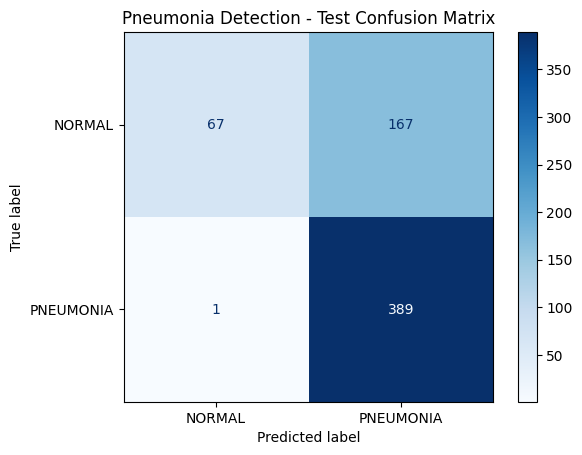

True Negatives: 67
False Positives: 167
False Negatives: 1
True Positives: 389


In [52]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Get actual labels
y_true = np.concatenate([
    labels.numpy().ravel()
    for images, labels in test_ds
]).astype(int)

# Get model predictions
y_scores = model.predict(test_ds).ravel()

# Convert prediction scores into classes
y_pred = (y_scores >= 0.5).astype(int)

# Calculate confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

# Display results
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["NORMAL", "PNEUMONIA"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Pneumonia Detection - Test Confusion Matrix")
plt.show()

print("True Negatives:", cm[0, 0])
print("False Positives:", cm[0, 1])
print("False Negatives:", cm[1, 0])
print("True Positives:", cm[1, 1])


In [53]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# Take one batch from the test dataset
images, labels = next(iter(test_ds))

# Select the first X-ray
image = images[0:1]

# Get its true label
true_label = int(labels[0].numpy())

# Get the CNN prediction
prediction = float(model.predict(image, verbose=0)[0][0])

print("True label:", ["NORMAL", "PNEUMONIA"][true_label])
print("Predicted label:",
      "PNEUMONIA" if prediction >= 0.5 else "NORMAL")
print("Pneumonia score:", round(prediction, 4))


/tmp/ipykernel_899/967516562.py:12: DeprecationWarning:

Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)



True label: NORMAL
Predicted label: PNEUMONIA
Pneumonia score: 0.5852


In [54]:

import tensorflow as tf
import numpy as np

# Create a symbolic input
inputs = tf.keras.Input(shape=(224, 224, 1))

# Pass the input through our trained CNN layers
x = inputs
last_conv_output = None

for layer in model.layers:
    x = layer(x)

    # Save the output of the last convolutional layer
    if isinstance(layer, tf.keras.layers.Conv2D):
        last_conv_output = x

# Create the Grad-CAM model
grad_model = tf.keras.Model(
    inputs=inputs,
    outputs=[last_conv_output, x]
)

print("Grad-CAM model created successfully!")


Grad-CAM model created successfully!


In [55]:

def make_gradcam_heatmap(img_array):

    with tf.GradientTape() as tape:

        conv_outputs, predictions = grad_model(
            img_array,
            training=False
        )

        # Explain the PNEUMONIA score
        target_score = predictions[:, 0]

    # Calculate gradients
    grads = tape.gradient(
        target_score,
        conv_outputs
    )

    # Average gradients across image positions
    pooled_grads = tf.reduce_mean(
        grads,
        axis=(0, 1, 2)
    )

    # Get feature maps for our image
    conv_outputs = conv_outputs[0]

    # Calculate the weighted heatmap
    heatmap = tf.reduce_sum(
        conv_outputs * pooled_grads,
        axis=-1
    )

    # Keep positive contributions
    heatmap = tf.maximum(heatmap, 0)

    # Normalize between 0 and 1
    heatmap = heatmap / (
        tf.reduce_max(heatmap) + 1e-8
    )

    return heatmap.numpy()


# Generate the heatmap
heatmap = make_gradcam_heatmap(image)

print("Heatmap generated successfully!")
print("Heatmap shape:", heatmap.shape)

Heatmap generated successfully!
Heatmap shape: (52, 52)


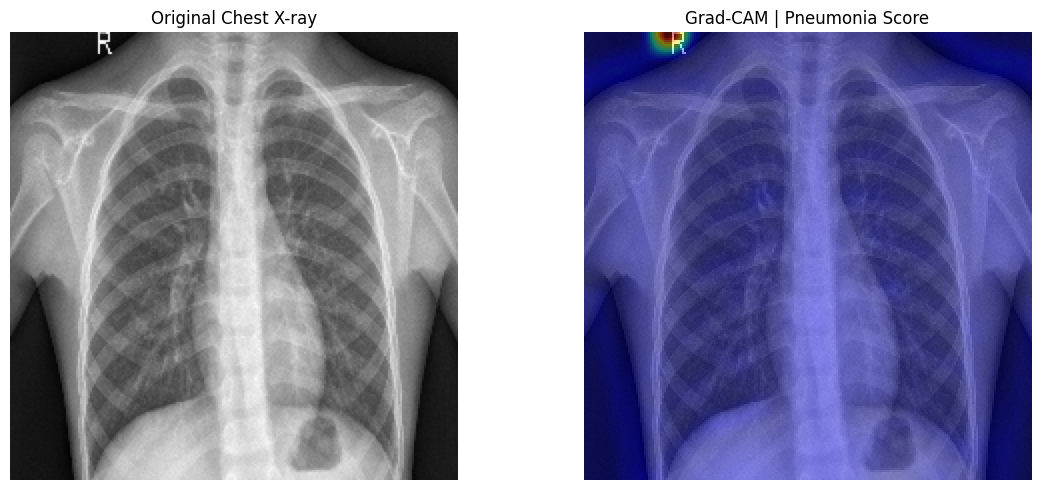

In [56]:

import matplotlib.pyplot as plt

# Resize heatmap to match the X-ray
heatmap_resized = tf.image.resize(
    heatmap[..., np.newaxis],
    (224, 224)
).numpy().squeeze()

# Extract the X-ray image
xray = image[0, :, :, 0].numpy()

plt.figure(figsize=(12, 5))

# Original X-ray
plt.subplot(1, 2, 1)
plt.imshow(xray, cmap="gray")
plt.title("Original Chest X-ray")
plt.axis("off")

# Grad-CAM overlay
plt.subplot(1, 2, 2)
plt.imshow(xray, cmap="gray")
plt.imshow(
    heatmap_resized,
    cmap="jet",
    alpha=0.45
)
plt.title("Grad-CAM | Pneumonia Score")
plt.axis("off")

plt.tight_layout()
plt.show()


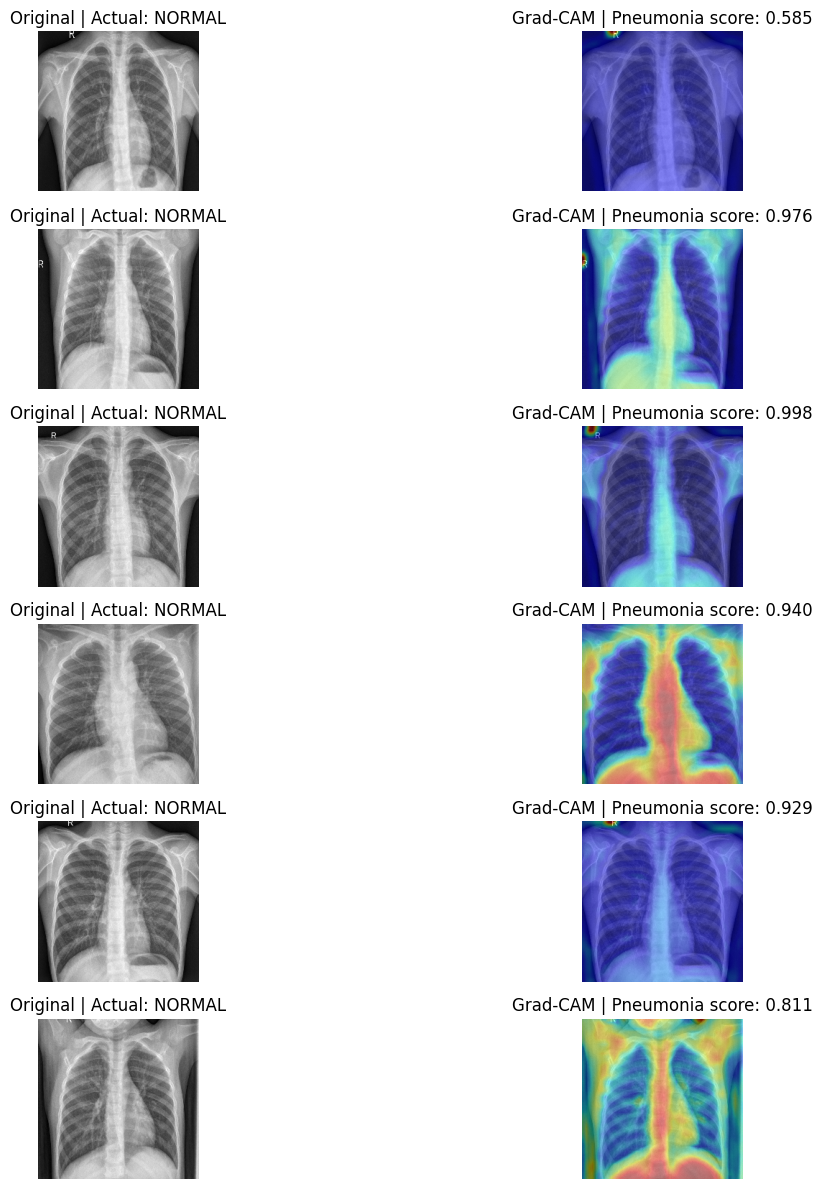

In [57]:

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf

# Take a batch of test images
images, labels = next(iter(test_ds))

plt.figure(figsize=(15, 12))

for i in range(6):

    # Select one image
    img = images[i:i+1]

    # Predict pneumonia score
    score = float(model(img, training=False).numpy()[0, 0])

    # Generate Grad-CAM
    heatmap = make_gradcam_heatmap(img)

    # Resize heatmap
    heatmap = tf.image.resize(
        heatmap[..., np.newaxis],
        (224, 224)
    ).numpy().squeeze()

    # Original X-ray
    xray = img[0, :, :, 0].numpy()

    # Show original
    plt.subplot(6, 2, 2*i + 1)
    plt.imshow(xray, cmap="gray")
    plt.title(
        f"Original | Actual: "
        f"{'PNEUMONIA' if int(labels[i]) else 'NORMAL'}"
    )
    plt.axis("off")

    # Show Grad-CAM
    plt.subplot(6, 2, 2*i + 2)
    plt.imshow(xray, cmap="gray")
    plt.imshow(
        heatmap,
        cmap="jet",
        alpha=0.45,
        vmin=0,
        vmax=1
    )
    plt.title(f"Grad-CAM | Pneumonia score: {score:.3f}")
    plt.axis("off")

plt.tight_layout()
plt.show()


Original pneumonia score: 0.5852
Masked pneumonia score:   0.6021
Score change: +0.0169


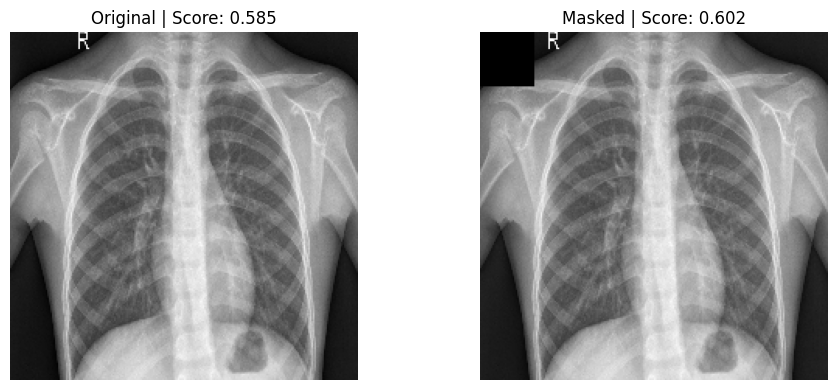

In [58]:

import numpy as np
import matplotlib.pyplot as plt

# Select the image you just analyzed
# Change the index if it was not the first image
index = 0

img = images[index:index+1].numpy().copy()

# Original prediction
original_score = float(
    model(img, training=False).numpy()[0, 0]
)

# Create a modified image
masked_img = img.copy()

# Mask the top-left corner
masked_img[:, :35, :35, :] = 0

# Prediction after masking
masked_score = float(
    model(masked_img, training=False).numpy()[0, 0]
)

print(f"Original pneumonia score: {original_score:.4f}")
print(f"Masked pneumonia score:   {masked_score:.4f}")
print(f"Score change: {masked_score - original_score:+.4f}")

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(img[0, :, :, 0], cmap="gray")
plt.title(f"Original | Score: {original_score:.3f}")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(masked_img[0, :, :, 0], cmap="gray")
plt.title(f"Masked | Score: {masked_score:.3f}")
plt.axis("off")

plt.tight_layout()
plt.show()


In [59]:

import numpy as np

# Predict all images in the current batch
scores = model.predict(images, verbose=0).ravel()

# Find the image with the highest score
highest_index = np.argmax(scores)

print("Image index:", highest_index)
print("Highest pneumonia score:", scores[highest_index])
print("Actual label:",
      "PNEUMONIA" if int(labels[highest_index]) == 1 else "NORMAL")


Image index: 9
Highest pneumonia score: 0.9991687
Actual label: NORMAL


In [60]:

def analyze_xray(image, model):
    # Predict the pneumonia score
    score = float(
        model(image, training=False).numpy()[0, 0]
    )

    print("=== AI CHEST X-RAY ANALYSIS ===")
    print(f"Pneumonia model score: {score:.3f}")

    if score >= 0.5:
        print("AI classification: PNEUMONIA")
        print("Attention: Medical review recommended.")
        print("This result is not a diagnosis.")
    else:
        print("AI classification: NORMAL")
        print("No pneumonia pattern classified by this model.")
        print("This does not rule out pneumonia.")

    return score


# Analyze the selected X-ray
score = analyze_xray(image, model)


=== AI CHEST X-RAY ANALYSIS ===
Pneumonia model score: 0.585
AI classification: PNEUMONIA
Attention: Medical review recommended.
This result is not a diagnosis.


In [61]:

def get_attention_level(score):
    """
    Educational review-priority categories.
    These thresholds are illustrative,
    not medically validated.
    """

    if score >= 0.80:
        return "HIGH", "Strong PNEUMONIA model output"

    elif score >= 0.50:
        return "MODERATE", "PNEUMONIA model output"

    elif score >= 0.20:
        return "UNCERTAIN", "Intermediate model score"

    else:
        return "LOW", "Strong NORMAL model output"


In [62]:

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

def analyze_xray_dashboard(image, true_label=None):

    # 1. Predict
    score = float(
        model(image, training=False).numpy()[0, 0]
    )

    predicted_class = (
        "PNEUMONIA" if score >= 0.5 else "NORMAL"
    )

    # 2. Calculate attention level
    attention, description = get_attention_level(score)

    # 3. Generate Grad-CAM
    heatmap = make_gradcam_heatmap(image)

    heatmap_resized = tf.image.resize(
        heatmap[..., np.newaxis],
        (224, 224)
    ).numpy().squeeze()

    # 4. Extract the X-ray
    xray = image[0, :, :, 0].numpy()

    # 5. Create dashboard
    fig, axes = plt.subplots(
        1, 2, figsize=(12, 5)
    )

    axes[0].imshow(xray, cmap="gray")
    axes[0].set_title("Original Chest X-ray")
    axes[0].axis("off")

    axes[1].imshow(xray, cmap="gray")
    axes[1].imshow(
        heatmap_resized,
        cmap="jet",
        alpha=0.45,
        vmin=0,
        vmax=1
    )
    axes[1].set_title("Grad-CAM | PNEUMONIA score")
    axes[1].axis("off")

    fig.suptitle(
        f"NEUROVISION AI | {predicted_class}\n"
        f"Score: {score:.3f} | "
        f"Review Priority: {attention}",
        fontsize=15,
        fontweight="bold"
    )

    plt.tight_layout()
    plt.show()

    # 6. Print explanation
    print("=== AI ANALYSIS REPORT ===")
    print("Predicted class:", predicted_class)
    print(f"Pneumonia model score: {score:.4f}")
    print("Review priority:", attention)
    print("Explanation:", description)

    if true_label is not None:
        print(
            "Dataset label:",
            "PNEUMONIA" if int(true_label) == 1
            else "NORMAL"
        )

    print(
        "\nEducational prototype only. "
        "Grad-CAM highlights model-influential regions, "
        "not confirmed lesions. "
        "All X-rays require clinical interpretation."
    )


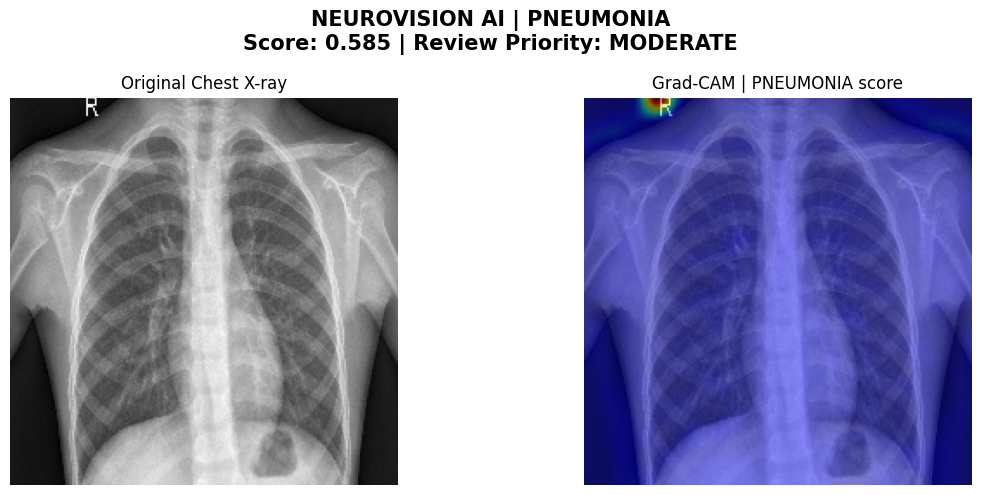

=== AI ANALYSIS REPORT ===
Predicted class: PNEUMONIA
Pneumonia model score: 0.5852
Review priority: MODERATE
Explanation: PNEUMONIA model output
Dataset label: NORMAL

Educational prototype only. Grad-CAM highlights model-influential regions, not confirmed lesions. All X-rays require clinical interpretation.


In [63]:

# Select an image from the test batch
index = 0

selected_image = images[index:index+1]
selected_label = labels[index]

# Run our dashboard
analyze_xray_dashboard(
    selected_image,
    true_label=selected_label
)


In [64]:

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

def show_xray_with_indicators(image):

    # 1. CNN prediction
    score = float(
        model(image, training=False).numpy()[0, 0]
    )

    if 0.4 <= score <= 0.6:
        prediction = "UNCERTAIN"
    elif score > 0.6:
        prediction = "PNEUMONIA"
    else:
        prediction = "NORMAL"

    # 2. Educational model-score indicator
    if score >= 0.8:
        level = "HIGH MODEL SCORE"
        color = "#EF4444"
    elif score >= 0.5:
        level = "POSITIVE MODEL SCORE"
        color = "#F59E0B"
    elif score >= 0.2:
        level = "INTERMEDIATE MODEL SCORE"
        color = "#3B82F6"
    else:
        level = "LOW MODEL SCORE"
        color = "#22C55E"

    # 3. Generate Grad-CAM
    heatmap = make_gradcam_heatmap(image)

    heatmap = tf.image.resize(
        heatmap[..., np.newaxis],
        (224, 224)
    ).numpy().squeeze()

    # 4. Find strongest Grad-CAM activation
    y, x = np.unravel_index(
        np.argmax(heatmap),
        heatmap.shape
    )

    # 5. Extract X-ray
    xray = image[0, :, :, 0].numpy()

    # 6. Create figure
    fig, ax = plt.subplots(figsize=(9, 9))

    ax.imshow(
        xray,
        cmap="gray",
        vmin=0,
        vmax=1
    )

    # Grad-CAM overlay
    ax.imshow(
        heatmap,
        cmap="jet",
        alpha=0.35,
        vmin=0,
        vmax=1
    )

    # 7. Highlight strongest activation
    ax.scatter(
        x, y,
        s=160,
        facecolors="none",
        edgecolors="yellow",
        linewidths=2.5
    )

    ax.annotate(
        "Strongest Grad-CAM activation",
        xy=(x, y),
        xytext=(10, 195),
        color="white",
        fontsize=9,
        fontweight="bold",
        arrowprops=dict(
            arrowstyle="->",
            color="yellow",
            lw=2
        ),
        bbox=dict(
            facecolor="black",
            alpha=0.75,
            boxstyle="round,pad=0.4"
        )
    )

    # 8. Add Right and Left indicators
    # Assumes standard frontal X-ray orientation

    ax.text(
        15, 65,
        "R",
        color="white",
        fontsize=18,
        fontweight="bold",
        ha="center",
        va="center",
        bbox=dict(
            facecolor="#2563EB",
            edgecolor="white",
            boxstyle="round,pad=0.3"
        )
    )

    ax.text(
        209, 65,
        "L",
        color="white",
        fontsize=18,
        fontweight="bold",
        ha="center",
        va="center",
        bbox=dict(
            facecolor="#2563EB",
            edgecolor="white",
            boxstyle="round,pad=0.3"
        )
    )

    # 9. Prediction indicator
    ax.text(
        8, 12,
        f"AI: {prediction}\n"
        f"Pneumonia score: {score:.1%}",
        color="white",
        fontsize=11,
        fontweight="bold",
        va="top",
        bbox=dict(
            facecolor="#111827",
            alpha=0.9,
            boxstyle="round,pad=0.5"
        )
    )

    # 10. Model-score indicator
    ax.text(
        8, 220,
        level,
        color="white",
        fontsize=11,
        fontweight="bold",
        va="bottom",
        bbox=dict(
            facecolor=color,
            alpha=0.9,
            boxstyle="round,pad=0.5"
        )
    )

    ax.set_title(
        "NEUROVISION AI | Explainable X-ray Analysis",
        fontsize=14,
        fontweight="bold"
    )

    ax.axis("off")
    plt.tight_layout()
    plt.show()

    print("Predicted class:", prediction)
    print(f"Pneumonia model score: {score:.4f}")
    print("Model-score indicator:", level)
    print(
        "R = patient's right | "
        "L = patient's left"
    )
    print(
        "Educational prototype: orientation must be "
        "verified from original X-ray metadata or markers."
    )
    print(
        "Grad-CAM activation is not a confirmed lesion; "
        "model scores do not indicate medical severity."
    )


In [65]:

from sklearn.metrics import classification_report, roc_auc_score

print("CNN Classification Report")
print(
    classification_report(
        y_true,
        y_pred,
        target_names=["NORMAL", "PNEUMONIA"],
        zero_division=0
    )
)

print(
    "ROC-AUC:",
    round(roc_auc_score(y_true, y_scores), 3)
)


CNN Classification Report
              precision    recall  f1-score   support

      NORMAL       0.99      0.29      0.44       234
   PNEUMONIA       0.70      1.00      0.82       390

    accuracy                           0.73       624
   macro avg       0.84      0.64      0.63       624
weighted avg       0.81      0.73      0.68       624

ROC-AUC: 0.916


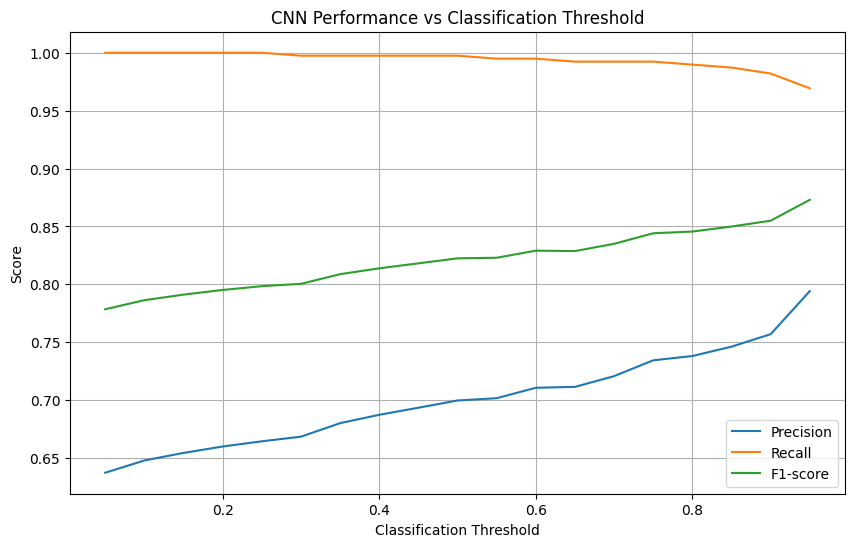

In [66]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

thresholds = np.arange(0.05, 1.0, 0.05)

precisions = []
recalls = []
f1_scores = []

for threshold in thresholds:
    predictions = (np.array(y_scores) >= threshold).astype(int)

    precisions.append(
        precision_score(y_true, predictions, zero_division=0)
    )

    recalls.append(
        recall_score(y_true, predictions, zero_division=0)
    )

    f1_scores.append(
        f1_score(y_true, predictions, zero_division=0)
    )

plt.figure(figsize=(10, 6))

plt.plot(thresholds, precisions, label="Precision")
plt.plot(thresholds, recalls, label="Recall")
plt.plot(thresholds, f1_scores, label="F1-score")

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("CNN Performance vs Classification Threshold")
plt.legend()
plt.grid(True)
plt.show()

In [67]:

import numpy as np
import matplotlib.pyplot as plt

# Collect test images and their actual labels
test_images = []
test_labels = []

for batch_images, batch_labels in test_ds:
    test_images.append(batch_images.numpy())
    test_labels.append(batch_labels.numpy().ravel())

test_images = np.concatenate(test_images)
test_labels = np.concatenate(test_labels).astype(int)

# Get predictions from our CNN
scores = model.predict(test_ds, verbose=0).ravel()
predictions = (scores >= 0.5).astype(int)

# Find incorrect predictions
false_positive_indices = np.where(
    (test_labels == 0) & (predictions == 1)
)[0]

false_negative_indices = np.where(
    (test_labels == 1) & (predictions == 0)
)[0]

print("False Positives:", len(false_positive_indices))
print("False Negatives:", len(false_negative_indices))


False Positives: 167
False Negatives: 1


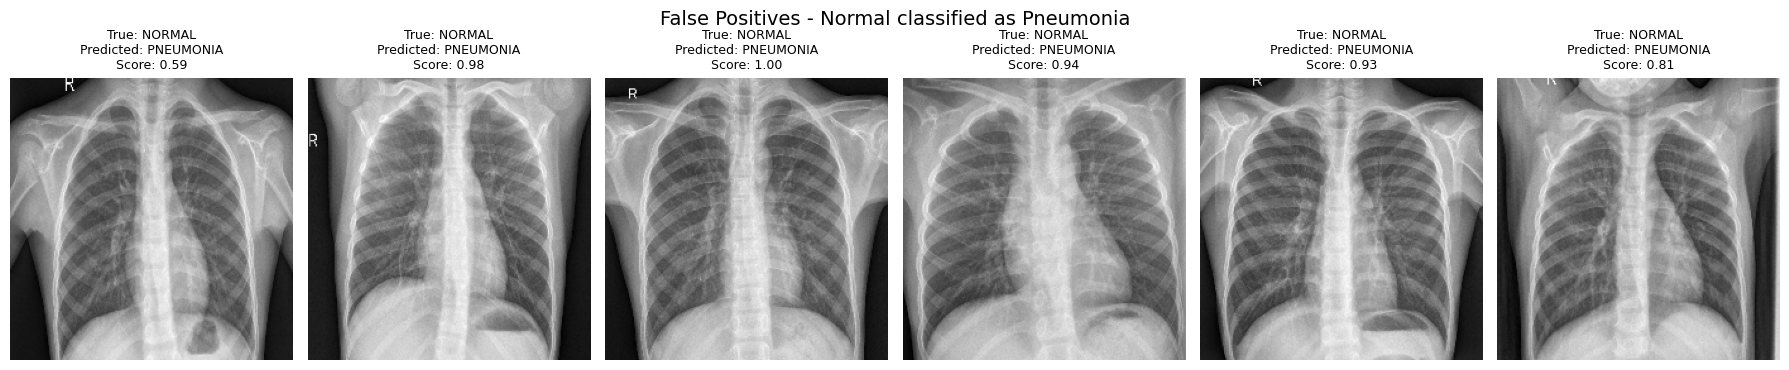

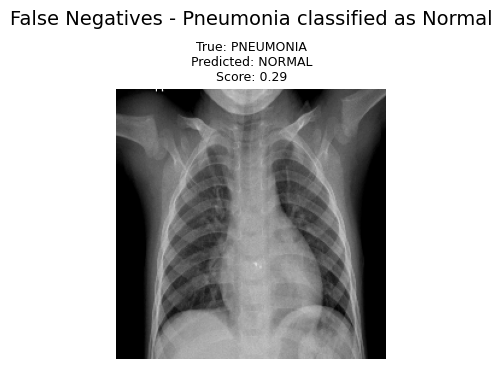

In [68]:

def show_errors(indices, title, max_images=6):

    selected = indices[:max_images]

    if len(selected) == 0:
        print("No errors found for:", title)
        return

    fig, axes = plt.subplots(
        1, len(selected),
        figsize=(3 * len(selected), 4),
        squeeze=False
    )

    for ax, idx in zip(axes[0], selected):
        image = test_images[idx].squeeze()

        ax.imshow(image, cmap="gray")
        ax.set_title(
            f"True: {['NORMAL', 'PNEUMONIA'][test_labels[idx]]}\n"
            f"Predicted: {['NORMAL', 'PNEUMONIA'][predictions[idx]]}\n"
            f"Score: {scores[idx]:.2f}",
            fontsize=9
        )
        ax.axis("off")

    fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()


show_errors(
    false_positive_indices,
    "False Positives - Normal classified as Pneumonia"
)

show_errors(
    false_negative_indices,
    "False Negatives - Pneumonia classified as Normal"
)

In [69]:

# Save the trained CNN model
model.save("pneumonia_cnn.keras")

print("Model saved successfully!")


Model saved successfully!


In [70]:

from google.colab import files

files.download("pneumonia_cnn.keras")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>